# Tracking con SkillCorner Open Data

La posición de los 22 jugadores y del balón 10 veces por segundo, extraída por SkillCorner del video de la transmisión. Son 20 partidos de la A-League 2024/25 con licencia MIT; el tracking de cada uno pesa ~90 MB y se descarga una sola vez.

In [1]:
import matplotlib.pyplot as plt
from analista import Partido
from analista import graficos as gr
from analista.datos import skillcorner as sc

sc.partidos()

,partido_id,fecha,local,visitante
0,1874553,2024-11-23,Brisbane FC,Adelaide United
1,1886347,2024-11-30,Auckland FC,Newcastle
2,1899585,2024-12-07,Auckland FC,Wellington P FC
3,1925299,2024-12-21,Brisbane FC,Perth Glory
4,1927964,2024-12-22,Western Sydney,Wellington P FC
5,1953632,2024-12-31,CC Mariners,Melbourne City
6,1959846,2025-01-10,Melbourne V FC,Western United
7,1986691,2025-01-26,Western Sydney,Auckland FC
8,1996436,2025-02-01,Auckland FC,Macarthur FC
9,1996435,2025-02-01,Sydney FC,Adelaide United


In [2]:
p = Partido.skillcorner(1886347)       # Auckland FC 2 - 0 Newcastle Jets
p.tracking.head()

,cuadro,t,periodo,id,nombre,numero,equipo,rol,x,y,detectado
0,10,1.0,1,51009,R. Scott,1,B,arquero,39.63,0.08,False
1,10,1.0,1,176224,P. Cancar,4,B,campo,19.21,9.18,True
2,10,1.0,1,51649,A. Šušnjar,15,B,campo,21.83,-0.47,True
3,10,1.0,1,50983,D. Ingham,14,B,campo,1.16,32.47,True
4,10,1.0,1,735578,M. Natta,33,B,campo,18.88,-15.73,True


## Métricas del partido
Posesión (quién está a ≤2 m del balón), presión, forma del equipo y físico, todo calculado a partir de las posiciones.

In [3]:
r = p.metricas()["resumen"]
{k: r[k] for k in ("posesion_pct", "presion_sufrida", "forma")}

{'posesion_pct': {'A': 55.8, 'B': 44.2},
 'presion_sufrida': {'A': {'rivales_a_5m': 0.74,
   'dist_rival_mas_cercano': 4.56},
  'B': {'rivales_a_5m': 0.7, 'dist_rival_mas_cercano': 4.99}},
 'forma': {'A': {'n_visibles': 10.0,
   'ancho': 36.8,
   'profundidad': 32.4,
   'area': 823.2,
   'compacidad': 15.2,
   'altura_bloque': 44.1,
   'centroide_x': 5.7},
  'B': {'n_visibles': 10.0,
   'ancho': 37.2,
   'profundidad': 30.0,
   'area': 745.3,
   'compacidad': 14.4,
   'altura_bloque': 28.5,
   'centroide_x': -11.9}}}

In [4]:
p.fisico().query("rol != 'arquero'").sort_values("distancia_m", ascending=False).head(8)[["nombre", "equipo", "distancia_m", "vel_max", "seg_sprint"]]

,nombre,equipo,distancia_m,vel_max,seg_sprint
1,F. Gallegos,A,11214.939436,8.554397,21.9
0,L. Verstraete,A,10678.885548,7.459544,6.1
27,L. Gillion,A,10176.072908,9.024846,36.7
19,T. Aquilina,B,10167.593514,8.115634,26.0
7,C. Timmins,B,9918.250887,8.172286,14.1
20,K. Grozos,B,9900.453900,8.453166,12.1
13,F. De Vries,A,9322.796548,8.071603,14.9
12,C. Elliott,A,9136.246159,10.197489,19.9


## Formación sin balón

In [5]:
{eq: p.formacion(eq)["formacion"] for eq in "AB"}

{'A': '4-2-3-1', 'B': '4-2-2-2'}

## Control de cancha un segundo antes del primer gol
Modelo de tiempo de llegada: cada punto se colorea según qué equipo llega antes (reacción 0,7 s, 5 m/s).

   cuadro       t equipo    jugador
0   50599  5059.9      A  N. Moreno
1   53790  5379.0      A    M. Mata


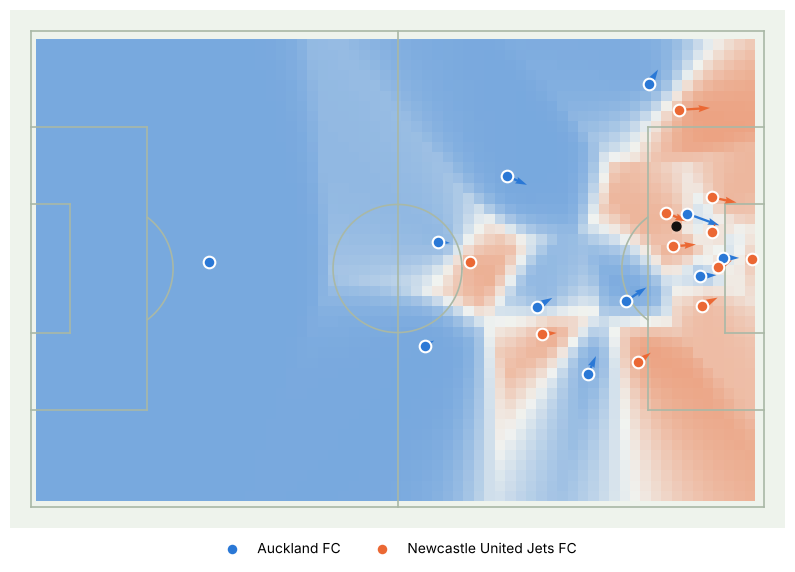

In [6]:
g = p.goles()
print(g)
gr.control_de_cancha(p, t=float(g.t.iloc[0]) - 1.0);

In [7]:
p.reporte("aleague_1886347.html")

PosixPath('aleague_1886347.html')